# 02 · Baseline sentiment models
Objective: classify each review as **Positive / Neutral / Negative** with traditional ML, to
(a) set the benchmark BERT has to beat and (b) learn which preprocessing/features matter.

**Experiment grid** (every run is tracked in MLflow):
preprocessing (stop-word removal on/off) × features (word 1–2, 1–3, word+char TF-IDF) × model
(Logistic Regression, Linear SVM, Naive Bayes) × with/without the rating as an extra feature × hyper-parameter.

Hyper-parameters are chosen on the **validation** set; the **test** set is never used for selection.
> Set `FULL_GRID = False` below for a ~4× faster run with a reduced hyper-parameter grid.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import itertools, time
from pathlib import Path
import mlflow, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support, classification_report
from sklearn.naive_bayes import MultinomialNB
from sklearn.preprocessing import OneHotEncoder
from sklearn.svm import LinearSVC

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC, OUT = ROOT / "data" / "processed", ROOT / "outputs"
OUT.mkdir(exist_ok=True)
SEED = 42
LABELS = ["negative", "neutral", "positive"]; L2I = {l: i for i, l in enumerate(LABELS)}
MLFLOW_URI = f"sqlite:///{ROOT / 'mlflow.db'}"
FULL_GRID = True
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def metrics(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1, 2], average=None, zero_division=0)
    pm, rm, fm, _ = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1, 2], average="macro", zero_division=0)
    out = {"accuracy": accuracy_score(y_true, y_pred), "precision_macro": pm, "recall_macro": rm, "f1_macro": fm}
    for i, l in enumerate(LABELS):
        out[f"precision_{l}"], out[f"recall_{l}"], out[f"f1_{l}"] = p[i], r[i], f[i]
    return out

def plot_confusion(y_true, y_pred, title, ax):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
    ax.imshow(cm, cmap="Blues"); ax.set_xticks(range(3), LABELS, rotation=30); ax.set_yticks(range(3), LABELS)
    ax.set(xlabel="Predicted", ylabel="True", title=title)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")

def load_split(name):
    d = pd.read_csv(PROC / f"{name}.csv"); d["y"] = d.sentiment_label.map(L2I); return d

tr, va, te = load_split("train"), load_split("val"), load_split("test")
print(len(tr), len(va), len(te))

24616 4921 4923


## Experiment definitions

In [2]:
FEATS = {   # name -> (preprocessing, word n-grams, add char n-grams?)
    "light_w12":       ("light",  (1, 2), False),
    "light_w13":       ("light",  (1, 3), False),
    "light_w12_char":  ("light",  (1, 2), True),
    "nostop_w12":      ("nostop", (1, 2), False),
}
GRID = ({"logreg": [1, 3, 10, 30], "linsvm": [0.1, 0.3, 1, 3], "nb": [0.03, 0.1, 0.3, 1]} if FULL_GRID else
        {"logreg": [1, 10], "linsvm": [0.3, 1], "nb": [0.1, 0.3]})

def make_model(name, p):
    if name == "logreg": return LogisticRegression(C=p, max_iter=3000, random_state=SEED)
    if name == "linsvm": return LinearSVC(C=p, random_state=SEED)
    return MultinomialNB(alpha=p)

def build_features(prep, ngram, char, use_rating):
    """Fit vectorisers on TRAIN only, transform val/test."""
    vecs = [TfidfVectorizer(ngram_range=ngram, min_df=2, sublinear_tf=True,
                            stop_words="english" if prep == "nostop" else None)]
    if char:
        vecs.append(TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, sublinear_tf=True, max_features=200_000))
    mats = [[v.fit_transform(tr.review_text) for v in vecs]] + [[v.transform(d.review_text) for v in vecs] for d in (va, te)]
    if use_rating:                       # rating in 0.5-wide bins, one-hot (captures the band structure)
        ohe = OneHotEncoder(handle_unknown="ignore")
        mats[0].append(ohe.fit_transform(tr[["rating_bin"]].astype(str)))
        mats[1].append(ohe.transform(va[["rating_bin"]].astype(str)))
        mats[2].append(ohe.transform(te[["rating_bin"]].astype(str)))
    return [hstack(m).tocsr() for m in mats]

## Run the grid (logged to MLflow)

In [3]:
mlflow.set_tracking_uri(MLFLOW_URI)
mlflow.set_experiment("guest-sentiment-baselines")
rows = []
t_start = time.time()
for (fname, (prep, ng, ch)), use_rating in itertools.product(FEATS.items(), [False, True]):
    Xtr, Xva, Xte = build_features(prep, ng, ch, use_rating)
    for mname, params in GRID.items():
        for p in params:
            t0 = time.time()
            m = make_model(mname, p).fit(Xtr, tr.y)
            mv, mt = metrics(va.y, m.predict(Xva)), metrics(te.y, m.predict(Xte))
            with mlflow.start_run(run_name=f"{mname}|{fname}|rating={use_rating}|p={p}"):
                mlflow.log_params({"model": mname, "features": fname, "prep": prep, "use_rating": use_rating,
                                   "hyperparam": p, "ngram": str(ng), "char": ch, "seed": SEED})
                mlflow.log_metrics({f"val_{k}": v for k, v in mv.items()})
                mlflow.log_metrics({f"test_{k}": v for k, v in mt.items()})
                mlflow.log_metric("fit_seconds", time.time() - t0)
            rows.append({"model": mname, "features": fname, "use_rating": use_rating, "hyperparam": p,
                         "val_acc": mv["accuracy"], "val_f1": mv["f1_macro"],
                         "test_acc": mt["accuracy"], "test_f1": mt["f1_macro"]})
    print(f"done {fname:15s} rating={use_rating!s:5}  ({time.time() - t_start:.0f}s)")
res = pd.DataFrame(rows)
res.to_csv(OUT / "baseline_all_runs.csv", index=False)
print(len(res), "runs")

2026/10/10 20:25:17 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/10 20:25:17 INFO mlflow.store.db.utils: Updating database tables


2026/10/10 20:25:19 INFO mlflow.tracking.fluent: Experiment with name 'guest-sentiment-baselines' does not exist. Creating a new experiment.


done light_w12       rating=False  (10s)


done light_w12       rating=True   (23s)


...

done light_w13       rating=True   (56s)


done light_w12_char  rating=False  (168s)


done light_w12_char  rating=True   (288s)


done nostop_w12      rating=False  (294s)


done nostop_w12      rating=True   (303s)
96 runs


## Best hyper-parameter per configuration (selected on validation F1)

In [4]:
best = (res.sort_values("val_f1", ascending=False)
           .groupby(["model", "features", "use_rating"], as_index=False).first()
           .sort_values("val_f1", ascending=False))
best.to_csv(OUT / "baseline_best_per_config.csv", index=False)
best.head(12).round(4)

,model,features,use_rating,hyperparam,val_acc,val_f1,test_acc,test_f1
9,logreg,light_w12,True,1.00,0.9453,0.9468,0.9427,0.9441
11,logreg,light_w12_char,True,1.00,0.9449,0.9463,0.9427,0.9441
13,logreg,light_w13,True,1.00,0.9447,0.9462,0.9429,0.9442
7,linsvm,nostop_w12,True,0.10,0.9447,0.9460,0.9439,0.9452
15,logreg,nostop_w12,True,1.00,0.9445,0.9459,0.9454,0.9466
3,linsvm,light_w12_char,True,0.10,0.9443,0.9457,0.9427,0.9440
23,nb,nostop_w12,True,0.03,0.9441,0.9455,0.9441,0.9455
1,linsvm,light_w12,True,0.10,0.9439,0.9454,0.9425,0.9438
5,linsvm,light_w13,True,0.10,0.9439,0.9453,0.9433,0.9446
21,nb,light_w13,True,0.03,0.9425,0.9440,0.9423,0.9437


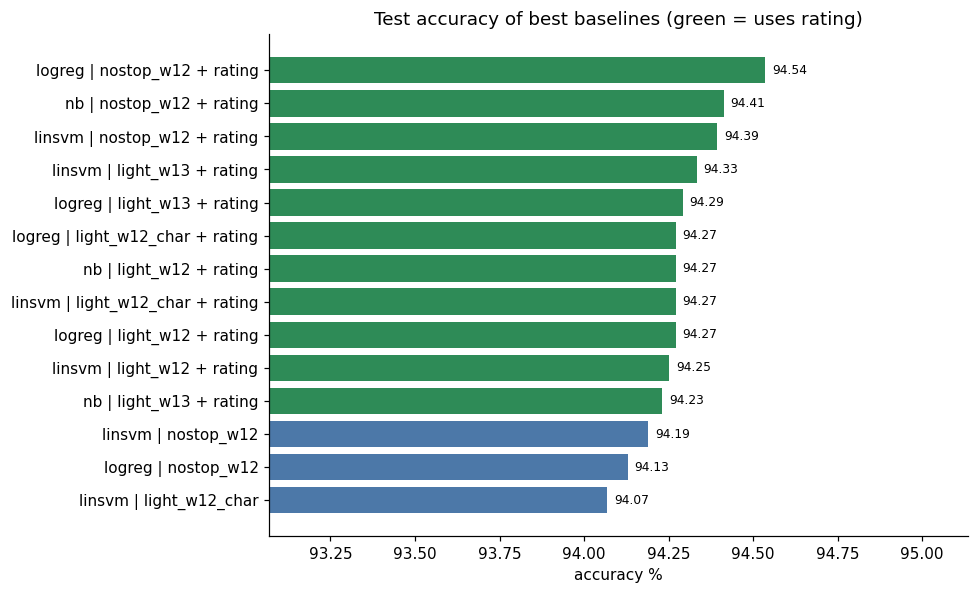

In [5]:
b = best.assign(setup=lambda d: d.model + " | " + d.features + np.where(d.use_rating, " + rating", ""))
b = b.sort_values("test_acc").tail(14)
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(b.setup, b.test_acc * 100, color=np.where(b.use_rating, "#2E8B57", "#4C78A8"))
ax.set_xlim(b.test_acc.min() * 100 - 1, b.test_acc.max() * 100 + .6)
for i, v in enumerate(b.test_acc * 100): ax.text(v + .02, i, f"{v:.2f}", va="center", fontsize=8)
ax.set(title="Test accuracy of best baselines (green = uses rating)", xlabel="accuracy %")
plt.tight_layout(); plt.show()

**What the grid says:** stop-word removal and bigger n-grams change accuracy by tenths of a point at most, the
three model families end up within ~1 point of each other, and adding the rating helps only marginally.
A plateau this flat points at the *labels* (see notebook 03), not at the models.

## Refit the single best configuration per setup, inspect errors

text_only         linsvm / light_w12_char / p=0.3  →  test accuracy 0.9407


text_plus_rating  logreg / light_w12 / p=1.0  →  test accuracy 0.9427


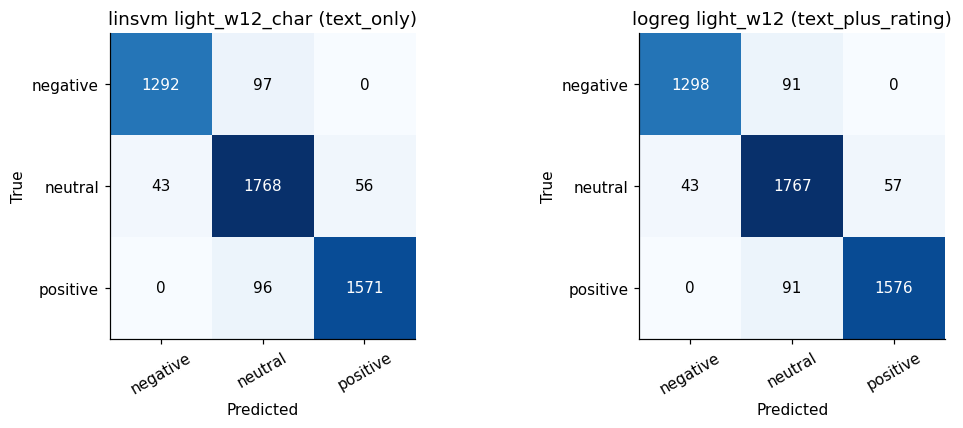

In [6]:
final = {}
for tag, sub in (("text_only", best[~best.use_rating]), ("text_plus_rating", best[best.use_rating])):
    r = sub.iloc[0]
    prep, ng, ch = FEATS[r.features]
    Xtr, Xva, Xte = build_features(prep, ng, ch, bool(r.use_rating))
    m = make_model(r.model, r.hyperparam).fit(Xtr, tr.y)
    pt = m.predict(Xte)
    final[tag] = (r, pt)
    pd.DataFrame({"review_id": te.review_id, "review_text": te.review_text, "rating_score": te.rating_score,
                  "true": te.y, "pred": pt}).to_csv(OUT / f"predictions_baseline_{tag}.csv", index=False)
    print(f"{tag:17s} {r.model} / {r.features} / p={r.hyperparam}  →  test accuracy {accuracy_score(te.y, pt):.4f}")

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for ax, (tag, (r, pt)) in zip(axs, final.items()):
    plot_confusion(te.y, pt, f"{r.model} {r.features} ({tag})", ax)
plt.tight_layout(); plt.savefig(OUT / "confusion_baseline.png", dpi=130); plt.show()

In [7]:
tag = "text_plus_rating"
print(classification_report(te.y, final[tag][1], target_names=LABELS, digits=3))

              precision    recall  f1-score   support

    negative      0.968     0.934     0.951      1389
     neutral      0.907     0.946     0.926      1867
    positive      0.965     0.945     0.955      1667

    accuracy                          0.943      4923
   macro avg      0.947     0.942     0.944      4923
weighted avg      0.944     0.943     0.943      4923

